<a href="https://colab.research.google.com/github/Apurva2006-beep/Practical-1/blob/main/Practical6_EE_505.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
classification_report
)

In [5]:
data = pd.read_csv("/content/Dataset 6.csv")

In [6]:
print("Dataset Preview:")
print(data.head())
print("\nDataset Columns:")
print(data.columns)

Dataset Preview:
   Signal_Strength_dBm  SNR_dB  Interference_dB  Distance_m  Frequency_GHz  \
0                  -41       6                0         257            5.0   
1                  -86      25               20         134            2.4   
2                  -73      27                0         385            2.4   
3                  -57       5                0         255            5.0   
4                  -87      15               24          61            5.0   

   Channel_Bandwidth_MHz  Noise_Floor_dBm  Connected_Devices  \
0                    160             -100                 24   
1                    160              -96                 41   
2                     20              -72                 13   
3                    160              -86                  9   
4                     20              -79                 32   

   Estimated_Throughput_Mbps Quality  
0                         18    Poor  
1                         55    Poor  
2           

In [8]:
import pandas as pd

# Fix incorrect parsing where all columns are merged into one string column
if len(data.columns) == 1 and ',' in data.columns[0]:
    col_names = data.columns[0].split(',')
    data = data.iloc[:, 0].str.split(',', expand=True)
    data.columns = col_names

# Convert columns back to numeric values
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Dynamically create our target variable using 'Signal_Strength_dBm'
print("Available Columns in Data:", list(data.columns))
print("\nCreating Signal Quality using Signal_Strength_dBm...")

data["Signal_Quality"] = data["Signal_Strength_dBm"].apply(
    lambda x: "Good" if x > -70 else "Poor"
)
y = data["Signal_Quality"]

Available Columns in Data: ['Signal_Strength_dBm', 'SNR_dB', 'Interference_dB', 'Distance_m', 'Frequency_GHz', 'Channel_Bandwidth_MHz', 'Noise_Floor_dBm', 'Connected_Devices', 'Estimated_Throughput_Mbps', 'Quality']

Creating Signal Quality using Signal_Strength_dBm...


In [9]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print("\nTarget Classes:")
print(encoder.classes_)


Target Classes:
['Good' 'Poor']


In [11]:
# Use the columns that actually exist in your dataset as features
X = data[
    [
        "Signal_Strength_dBm",
        "SNR_dB",
        "Interference_dB",
        "Distance_m",
        "Frequency_GHz",
        "Channel_Bandwidth_MHz",
        "Noise_Floor_dBm",
        "Connected_Devices",
        "Estimated_Throughput_Mbps"
    ]
]

In [12]:
# Fixing the typo from '_train' to 'X_train'
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y
)

In [13]:
model = SVC(
kernel="rbf",
C=1,
gamma="scale"
)
# Training
model.fit(
X_train,
y_train
)

SVC(C=1)

In [14]:
y_pred = model.predict(
X_test
)

In [15]:
print("\nAccuracy:")
print(
round(
accuracy_score(
y_test,
y_pred
)*100,
2
),
"%"
)
print("\nClassification Report:")
print(
classification_report(
y_test,
y_pred,
target_names=encoder.classes_
)
)


Accuracy:
65.0 %

Classification Report:
              precision    recall  f1-score   support

        Good       0.62      0.80      0.70        10
        Poor       0.71      0.50      0.59        10

    accuracy                           0.65        20
   macro avg       0.66      0.65      0.64        20
weighted avg       0.66      0.65      0.64        20



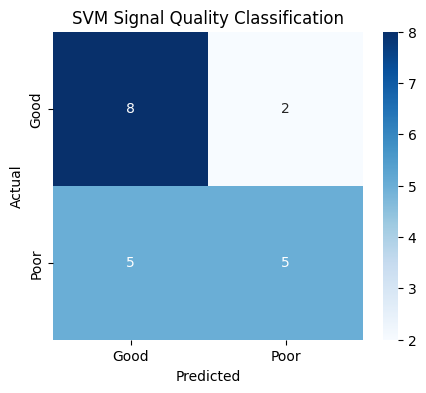

In [16]:
cm = confusion_matrix(
y_test,
y_pred
)
plt.figure(figsize=(5,4))
sns.heatmap(
cm,
annot=True,
fmt="d",
cmap="Blues",
xticklabels=encoder.classes_,
yticklabels=encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Signal Quality Classification")
plt.show()

In [20]:
# 1. Define a new signal sample as a DataFrame with matching 9 feature names
new_signal_df = pd.DataFrame([[
    -65, # Signal_Strength_dBm
    15,  # SNR_dB
    10,  # Interference_dB
    150, # Distance_m
    5.0, # Frequency_GHz
    80,  # Channel_Bandwidth_MHz
    -90, # Noise_Floor_dBm
    12,  # Connected_Devices
    45   # Estimated_Throughput_Mbps
]], columns=X_train.columns)

# 2. Scale the new signal using our fitted scaler
new_signal_scaled = scaler.transform(new_signal_df)

# 3. Predict using our trained SVM model
prediction = model.predict(new_signal_scaled)

print("\nNew Signal Quality:")
print(encoder.inverse_transform(prediction)[0])


New Signal Quality:
Good
